<b>DV Experiment 8: Time Series Forecasting and Trend Lines</b><br><br><b>Aim:</b> Apply linear trend lines, 3M/6M moving averages, 6M EMA, and Holt-Winters seasonal smoothing to forecast 6 future months with 95% confidence bounds.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error

In [2]:
data_dir = "datasets" if os.path.exists("datasets") else os.path.join("DV_Lab", "datasets")
out_dir = "outputs" if os.path.exists("outputs") else (os.path.join("DV_Lab", "outputs") if os.path.exists("DV_Lab") else "outputs")
os.makedirs(out_dir, exist_ok=True)

df = pd.read_csv(os.path.join(data_dir, "monthly_sales_stock.csv"))
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)

df["SMA_3M"] = df["Monthly_Sales"].rolling(window=3).mean()
df["SMA_6M"] = df["Monthly_Sales"].rolling(window=6).mean()
df["EMA_6M"] = df["Stock_Close"].ewm(span=6, adjust=False).mean()

t_idx = np.arange(len(df))
sales_slope, sales_intercept = np.polyfit(t_idx, df["Monthly_Sales"], 1)
df["Sales_Trend"] = sales_intercept + sales_slope * t_idx

stock_slope, stock_intercept = np.polyfit(t_idx, df["Stock_Close"], 1)
df["Stock_Trend"] = stock_intercept + stock_slope * t_idx

sales_series = df.set_index("Date")["Monthly_Sales"]

In [3]:
sales_series.index.freq = "MS"

train_ts = sales_series.iloc[:-6]
test_ts = sales_series.iloc[-6:]
val_model = ExponentialSmoothing(train_ts, trend="add", seasonal="add", seasonal_periods=12).fit()
val_forecast = val_model.forecast(6)
val_rmse = np.sqrt(mean_squared_error(test_ts, val_forecast))
val_mape = mean_absolute_percentage_error(test_ts, val_forecast) * 100.0

print(f"Holdout Validation (Last 6 Months) | RMSE: {val_rmse:.2f} | MAPE: {val_mape:.2f}%")

full_model = ExponentialSmoothing(sales_series, trend="add", seasonal="add", seasonal_periods=12).fit()
future_forecast = full_model.forecast(6)
resid_std = float(np.std(full_model.resid))
ci_upper = future_forecast + 1.96 * resid_std
ci_lower = future_forecast - 1.96 * resid_std

forecast_table = pd.DataFrame({
    "Forecast_Month": future_forecast.index.strftime("%Y-%m-%d"),
    "Predicted_Sales": np.round(future_forecast.values, 2),
    "Lower_95_CI": np.round(ci_lower.values, 2),
    "Upper_95_CI": np.round(ci_upper.values, 2),
})
print("\n6-Month Sales Forecast:")
print(forecast_table.to_string(index=False))

Holdout Validation (Last 6 Months) | RMSE: 826.23 | MAPE: 1.73%

6-Month Sales Forecast:
Forecast_Month  Predicted_Sales  Lower_95_CI  Upper_95_CI
    2026-01-01         38619.97     37561.31     39678.64
    2026-02-01         39691.73     38633.06     40750.39
    2026-03-01         40568.08     39509.42     41626.74
    2026-04-01         40925.99     39867.33     41984.65
    2026-05-01         44388.20     43329.54     45446.86
    2026-06-01         46578.05     45519.39     47636.71


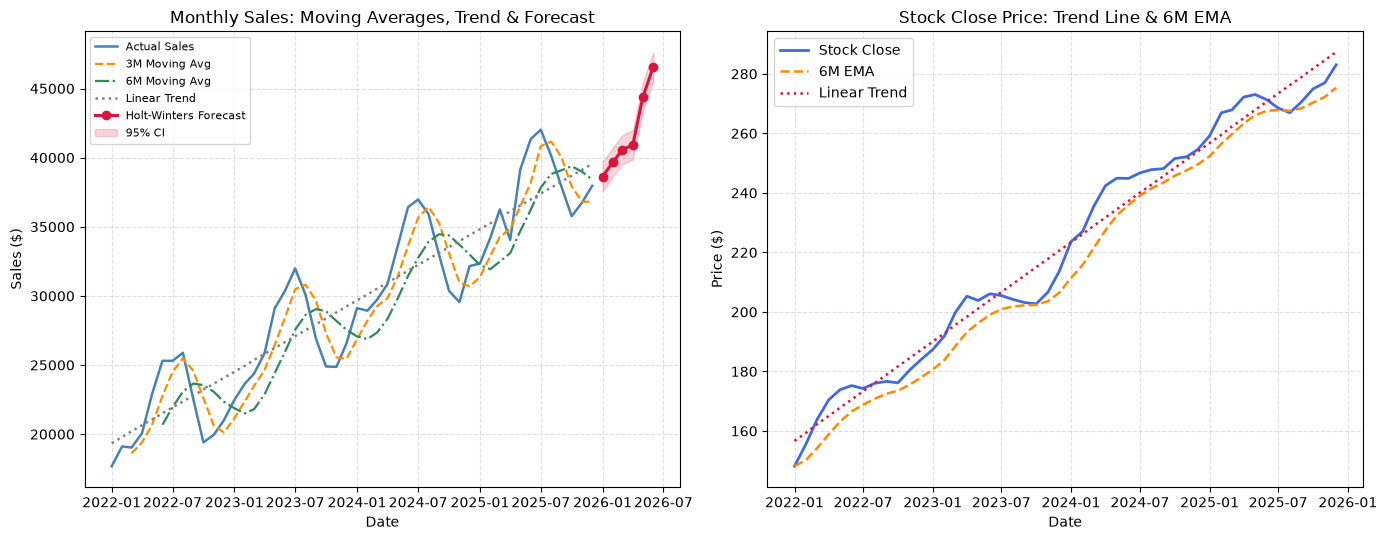

Interactive Forecast HTML saved to: outputs\DV_Exp8_Forecast_Interactive.html


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

axes[0].plot(df["Date"], df["Monthly_Sales"], color="steelblue", linewidth=1.8, label="Actual Sales")
axes[0].plot(df["Date"], df["SMA_3M"], color="darkorange", linestyle="--", linewidth=1.6, label="3M Moving Avg")
axes[0].plot(df["Date"], df["SMA_6M"], color="seagreen", linestyle="-.", linewidth=1.6, label="6M Moving Avg")
axes[0].plot(df["Date"], df["Sales_Trend"], color="gray", linestyle=":", linewidth=1.8, label="Linear Trend")
axes[0].plot(future_forecast.index, future_forecast.values, color="crimson", marker="o", linewidth=2.2, label="Holt-Winters Forecast")
axes[0].fill_between(future_forecast.index, ci_lower.values, ci_upper.values, color="crimson", alpha=0.18, label="95% CI")
axes[0].set_title("Monthly Sales: Moving Averages, Trend & Forecast")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Sales ($)")
axes[0].legend(fontsize=8)
axes[0].grid(True, linestyle="--", alpha=0.4)

axes[1].plot(df["Date"], df["Stock_Close"], color="royalblue", linewidth=2, label="Stock Close")
axes[1].plot(df["Date"], df["EMA_6M"], color="darkorange", linewidth=1.8, linestyle="--", label="6M EMA")
axes[1].plot(df["Date"], df["Stock_Trend"], color="crimson", linewidth=1.8, linestyle=":", label="Linear Trend")
axes[1].set_title("Stock Close Price: Trend Line & 6M EMA")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Price ($)")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

ts_fig = go.Figure()
ts_fig.add_trace(go.Scatter(x=df["Date"], y=df["Monthly_Sales"], mode="lines+markers", name="Actual Sales", line=dict(color="steelblue", width=2)))
ts_fig.add_trace(go.Scatter(x=df["Date"], y=df["SMA_6M"], mode="lines", name="6M Moving Average", line=dict(color="seagreen", dash="dash")))
ts_fig.add_trace(go.Scatter(x=df["Date"], y=df["Sales_Trend"], mode="lines", name="Linear Trend", line=dict(color="gray", dash="dot")))
ts_fig.add_trace(go.Scatter(x=future_forecast.index, y=future_forecast.values, mode="lines+markers", name="6M Forecast", line=dict(color="crimson", width=2.5)))
ts_fig.add_trace(go.Scatter(
    x=list(future_forecast.index) + list(future_forecast.index[::-1]),
    y=list(ci_upper.values) + list(ci_lower.values[::-1]),
    fill="toself",
    fillcolor="rgba(220, 20, 60, 0.15)",
    line=dict(color="rgba(255,255,255,0)"),
    name="95% Confidence Interval",
))
ts_fig.update_layout(height=540, width=1080, title="Interactive Time Series Forecasting & Trend Analysis", xaxis_title="Date", yaxis_title="Monthly Sales ($)")
html_path = os.path.join(out_dir, "DV_Exp8_Forecast_Interactive.html")
ts_fig.write_html(html_path, include_plotlyjs="cdn")
print("Interactive Forecast HTML saved to:", html_path)

<b>Observation:</b> Holt-Winters seasonal forecasting captures annual Q4 cycles accurately on holdout validation and projects future demand with confidence intervals.